# Fertilizer Recommendation System

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
df = pd.read_csv("crop_fertilizer_recommendation_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (2200, 13)


,N,P,K,temperature,humidity,ph,rainfall,label,fertilizer,N_status,P_status,K_status,recommendation_note
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,Balanced NPK (14-14-14),Normal,Normal,Normal,Based on NPK + climate conditions
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,Balanced NPK (14-14-14),Normal,Normal,Normal,Based on NPK + climate conditions
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,Balanced NPK (14-14-14),Normal,Normal,Normal,Based on NPK + climate conditions
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,DAP (Diammonium Phosphate),Normal,Low,Normal,Based on NPK + climate conditions
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,Balanced NPK (14-14-14),Normal,Normal,Normal,Based on NPK + climate conditions



Column Names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'fertilizer', 'N_status', 'P_status', 'K_status', 'recommendation_note']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   N                    2200 non-null   int64  
 1   P                    2200 non-null   int64  
 2   K                    2200 non-null   int64  
 3   temperature          2200 non-null   float64
 4   humidity             2200 non-null   float64
 5   ph                   2200 non-null   float64
 6   rainfall             2200 non-null   float64
 7   label                2200 non-null   object 
 8   fertilizer           2200 non-null   object 
 9   N_status             2200 non-null   object 
 10  P_status             2200 non-null   object 
 11  K_status             2200 non-null   object 
 12  recommen

In [14]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [16]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts())


label
Unique values: 22
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

fertilizer
Unique values: 5
fertilizer
Urea (Nitrogen rich fertilizer)    914
Balanced NPK (10-26-26)            378
DAP (Diammonium Phosphate)         371
MOP (Muriate of Potash)            274
Balanced NPK (14-14-14)            263
Name: count, dtype: int64

N_status
Unique values: 3
N_status
Low       1292
Normal     614
High       294
Name: count, dtype: int64

P_status
Unique values: 3
P_status
Normal    1192
Low        808
High       200
Name: count, dtype: int64

K_status
Unique values: 3
K_status
Low       1335

In [18]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
N                      0
P                      0
K                      0
temperature            0
humidity               0
ph                     0
rainfall               0
label                  0
fertilizer             0
N_status               0
P_status               0
K_status               0
recommendation_note    0
dtype: int64

Duplicate Rows: 0


In [20]:
for col in df.select_dtypes(include=np.number).columns:
    print(f"{col}: Min = {df[col].min():.2f}, Max = {df[col].max():.2f}")

N: Min = 0.00, Max = 140.00
P: Min = 5.00, Max = 145.00
K: Min = 5.00, Max = 205.00
temperature: Min = 8.83, Max = 43.68
humidity: Min = 14.26, Max = 99.98
ph: Min = 3.50, Max = 9.94
rainfall: Min = 20.21, Max = 298.56


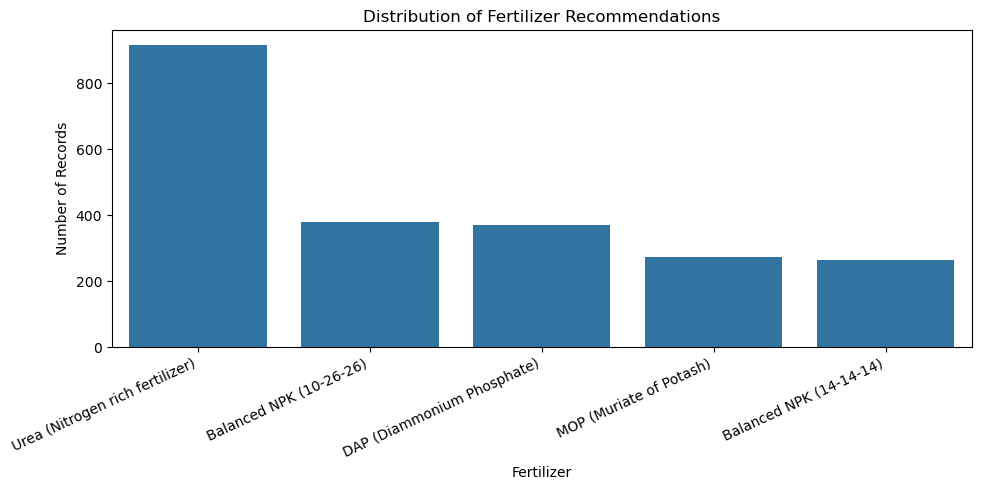

In [26]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='fertilizer',
    order=df['fertilizer'].value_counts().index
)

plt.title('Distribution of Fertilizer Recommendations')
plt.xlabel('Fertilizer')
plt.ylabel('Number of Records')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

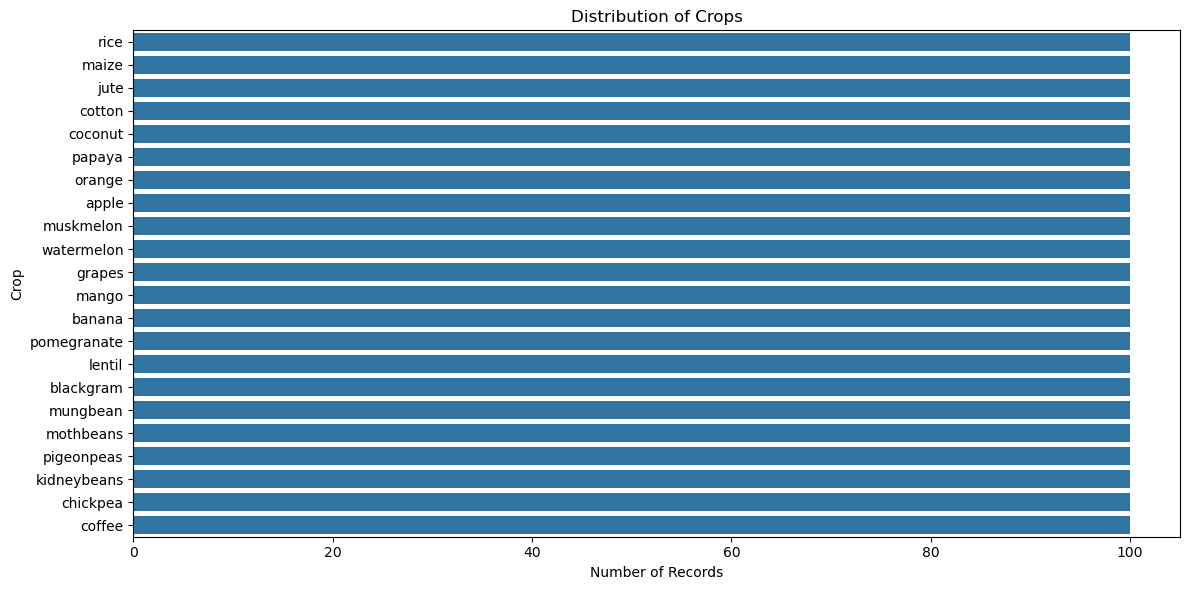

In [28]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='label',
    order=df['label'].value_counts().index
)

plt.title('Distribution of Crops')
plt.xlabel('Number of Records')
plt.ylabel('Crop')
plt.tight_layout()
plt.show()

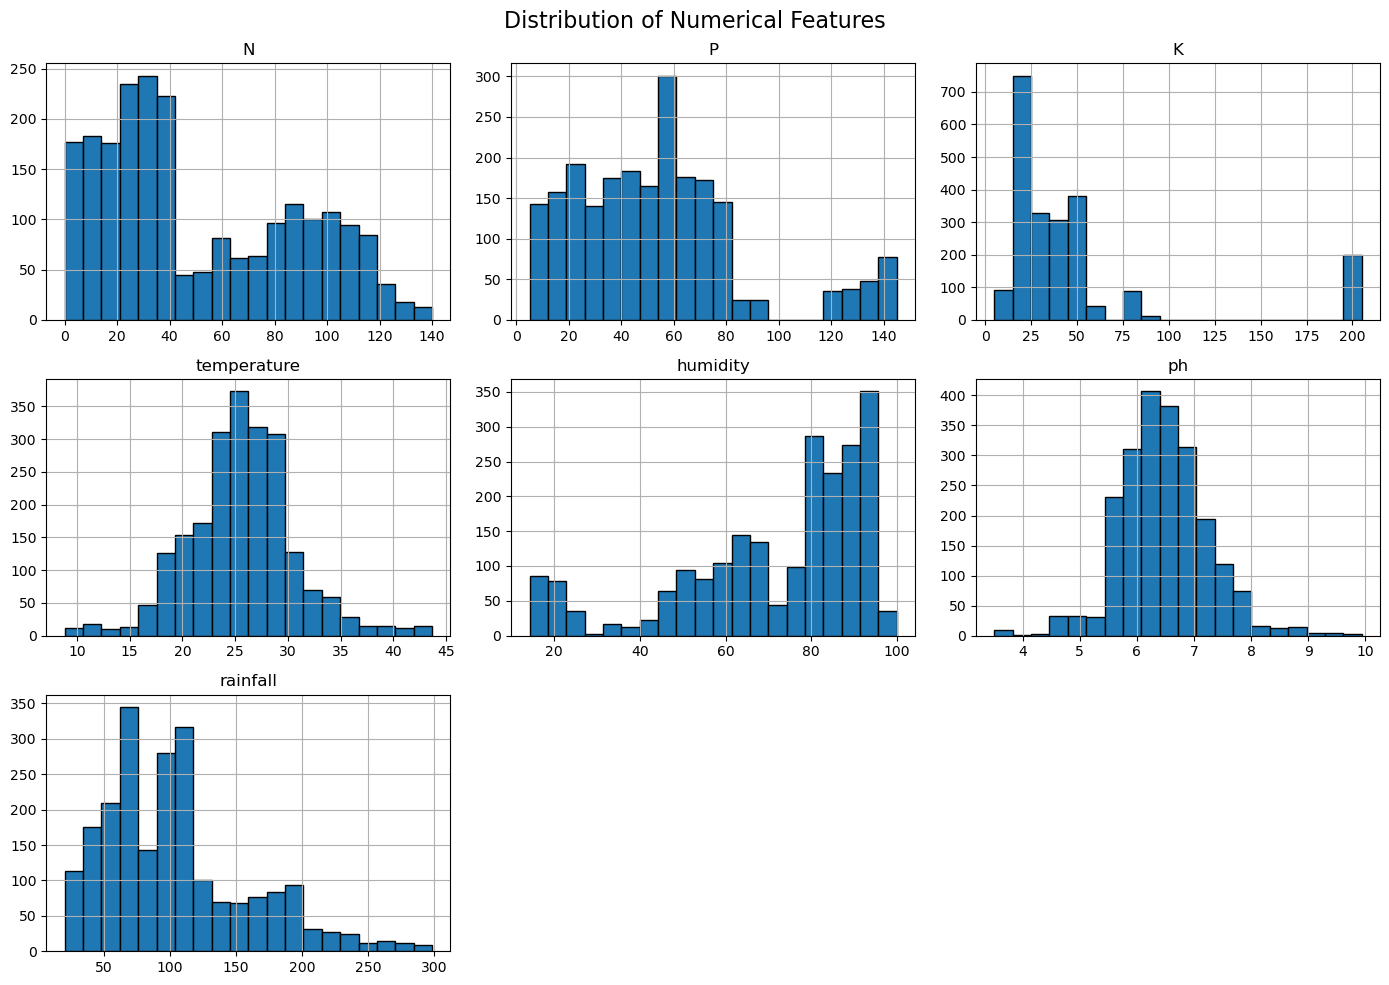

In [30]:
numerical_columns = [
    'N', 'P', 'K',
    'temperature', 'humidity',
    'ph', 'rainfall'
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

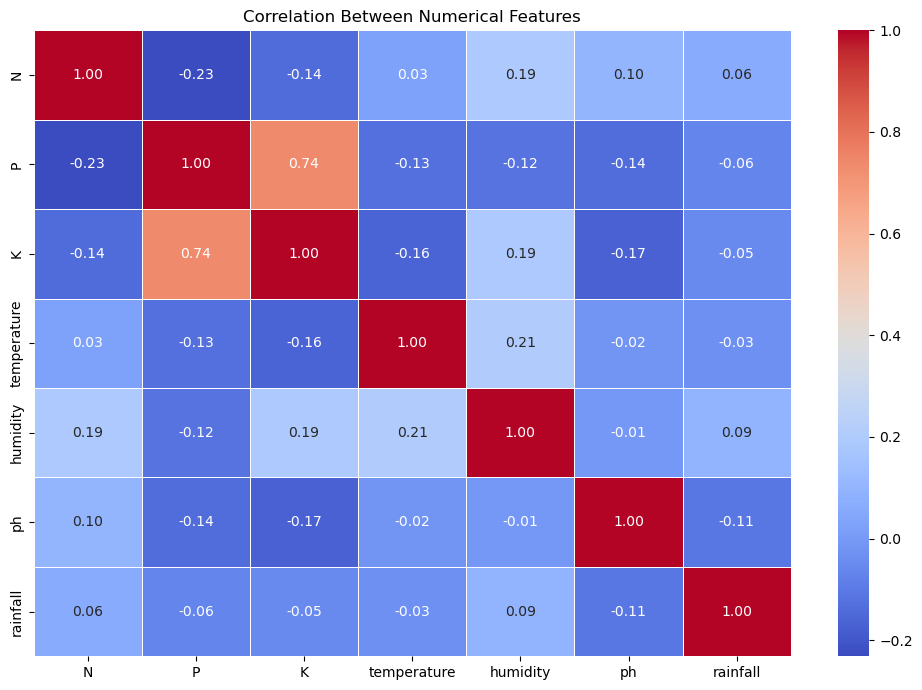

In [32]:
plt.figure(figsize=(10, 7))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

In [42]:
crop_fertilizer = pd.crosstab(
    df['label'],
    df['fertilizer']
)

display(crop_fertilizer)

fertilizer,Balanced NPK (10-26-26),Balanced NPK (14-14-14),DAP (Diammonium Phosphate),MOP (Muriate of Potash),Urea (Nitrogen rich fertilizer)
label,,,,,
apple,0,0,0,0,100
banana,0,100,0,0,0
blackgram,0,0,0,31,69
chickpea,0,28,0,0,72
coconut,100,0,0,0,0
coffee,0,0,91,9,0
cotton,0,0,24,76,0
grapes,0,0,0,0,100
jute,0,45,16,39,0


In [44]:
for col in ['N_status', 'P_status', 'K_status']:
    print(f"\nFertilizer distribution by {col}:")

    display(pd.crosstab(
        df[col],
        df['fertilizer'],
        normalize='index'
    ).round(3))


Fertilizer distribution by N_status:


fertilizer,Balanced NPK (10-26-26),Balanced NPK (14-14-14),DAP (Diammonium Phosphate),MOP (Muriate of Potash),Urea (Nitrogen rich fertilizer)
N_status,,,,,
High,0.000,0.170,0.571,0.259,0.000
Low,0.293,0.000,0.000,0.000,0.707
Normal,0.000,0.347,0.331,0.322,0.000



Fertilizer distribution by P_status:


fertilizer,Balanced NPK (10-26-26),Balanced NPK (14-14-14),DAP (Diammonium Phosphate),MOP (Muriate of Potash),Urea (Nitrogen rich fertilizer)
P_status,,,,,
High,0.000,0.000,0.000,0.00,1.000
Low,0.468,0.000,0.459,0.00,0.073
Normal,0.000,0.221,0.000,0.23,0.549



Fertilizer distribution by K_status:


fertilizer,Balanced NPK (10-26-26),Balanced NPK (14-14-14),DAP (Diammonium Phosphate),MOP (Muriate of Potash),Urea (Nitrogen rich fertilizer)
K_status,,,,,
High,0.000,0.000,0.000,0.000,1.000
Low,0.283,0.000,0.113,0.205,0.399
Normal,0.000,0.395,0.331,0.000,0.274


In [46]:
status_columns = {
    'N': 'N_status',
    'P': 'P_status',
    'K': 'K_status'
}

for nutrient, status in status_columns.items():
    print(f"\n{nutrient} values grouped by {status}:")

    display(
        df.groupby(status)[nutrient]
        .agg(['min', 'max', 'mean', 'count'])
        .round(2)
    )


N values grouped by N_status:


,min,max,mean,count
N_status,,,,
High,101,140,113.29,294
Low,0,49,22.81,1292
Normal,50,100,78.88,614



P values grouped by P_status:


,min,max,mean,count
P_status,,,,
High,120,145,133.38,200
Low,5,39,22.57,808
Normal,40,95,60.81,1192



K values grouped by K_status:


,min,max,mean,count
K_status,,,,
High,195,205,200.00,200
Low,5,39,23.14,1335
Normal,40,85,52.68,665


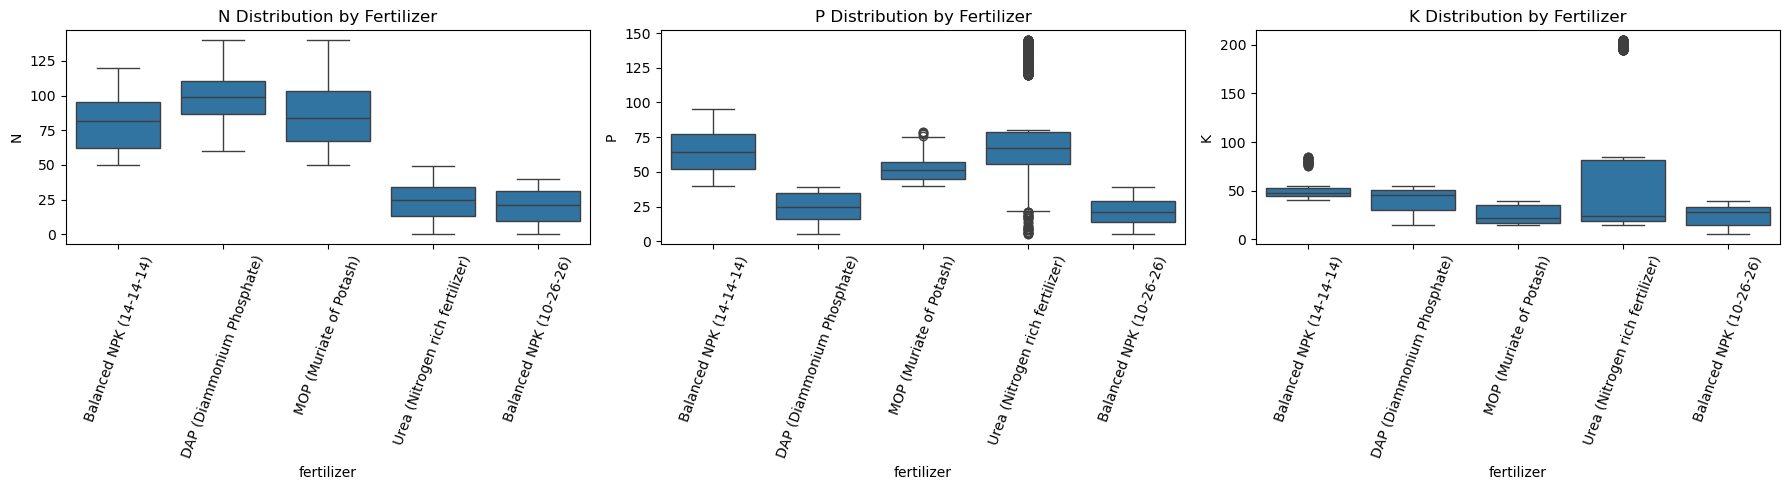

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nutrient in zip(axes, ['N', 'P', 'K']):
    sns.boxplot(
        data=df,
        x='fertilizer',
        y=nutrient,
        ax=ax
    )

    ax.set_title(f'{nutrient} Distribution by Fertilizer')
    ax.tick_params(axis='x', rotation=70)

plt.tight_layout()
plt.show()

In [50]:
crop_analysis = df.groupby('label').agg(
    Total_Records=('fertilizer', 'count'),
    Unique_Fertilizers=('fertilizer', 'nunique')
)

display(crop_analysis.sort_values('Unique_Fertilizers'))

,Total_Records,Unique_Fertilizers
label,,
apple,100,1
pigeonpeas,100,1
orange,100,1
muskmelon,100,1
kidneybeans,100,1
grapes,100,1
lentil,100,1
coconut,100,1
banana,100,1


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X_crop = df[['label']]
y = df['fertilizer']

X_train, X_test, y_train, y_test = train_test_split(
    X_crop, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

crop_model = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
    ('model', DecisionTreeClassifier(random_state=42))
])

crop_model.fit(X_train, y_train)

predictions = crop_model.predict(X_test)

print("Crop-only Accuracy:", accuracy_score(y_test, predictions))

Crop-only Accuracy: 0.8136363636363636


In [54]:
X_npk = df[['N', 'P', 'K']]

X_train, X_test, y_train, y_test = train_test_split(
    X_npk, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

npk_model = DecisionTreeClassifier(random_state=42)

npk_model.fit(X_train, y_train)

predictions = npk_model.predict(X_test)

print("NPK-only Accuracy:", accuracy_score(y_test, predictions))

NPK-only Accuracy: 1.0


In [56]:
features = [
    'N', 'P', 'K',
    'temperature', 'humidity',
    'ph', 'rainfall',
    'label'
]

X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), ['label'])
], remainder='passthrough')

full_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

full_model.fit(X_train, y_train)

predictions = full_model.predict(X_test)

print("All-features Accuracy:", accuracy_score(y_test, predictions))

All-features Accuracy: 1.0


,Feature,Importance
1,P,0.467099
0,N,0.304189
2,K,0.228712


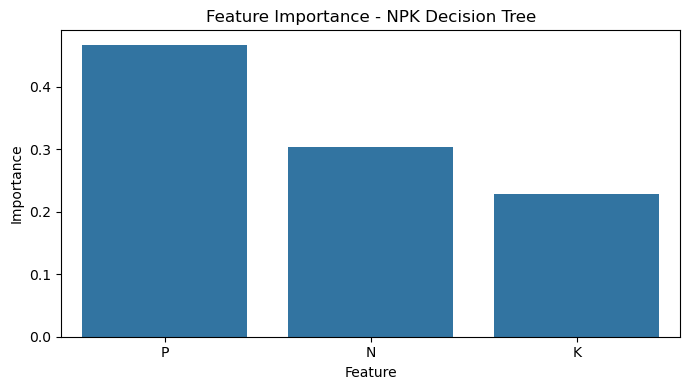

In [64]:
importance = pd.DataFrame({
    'Feature': ['N', 'P', 'K'],
    'Importance': npk_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=importance,
    x='Feature',
    y='Importance'
)

plt.title('Feature Importance - NPK Decision Tree')
plt.tight_layout()
plt.show()

In [66]:
print("Tree Depth:", npk_model.get_depth())
print("Number of Leaves:", npk_model.get_n_leaves())
print("Number of Nodes:", npk_model.tree_.node_count)

Tree Depth: 3
Number of Leaves: 6
Number of Nodes: 11


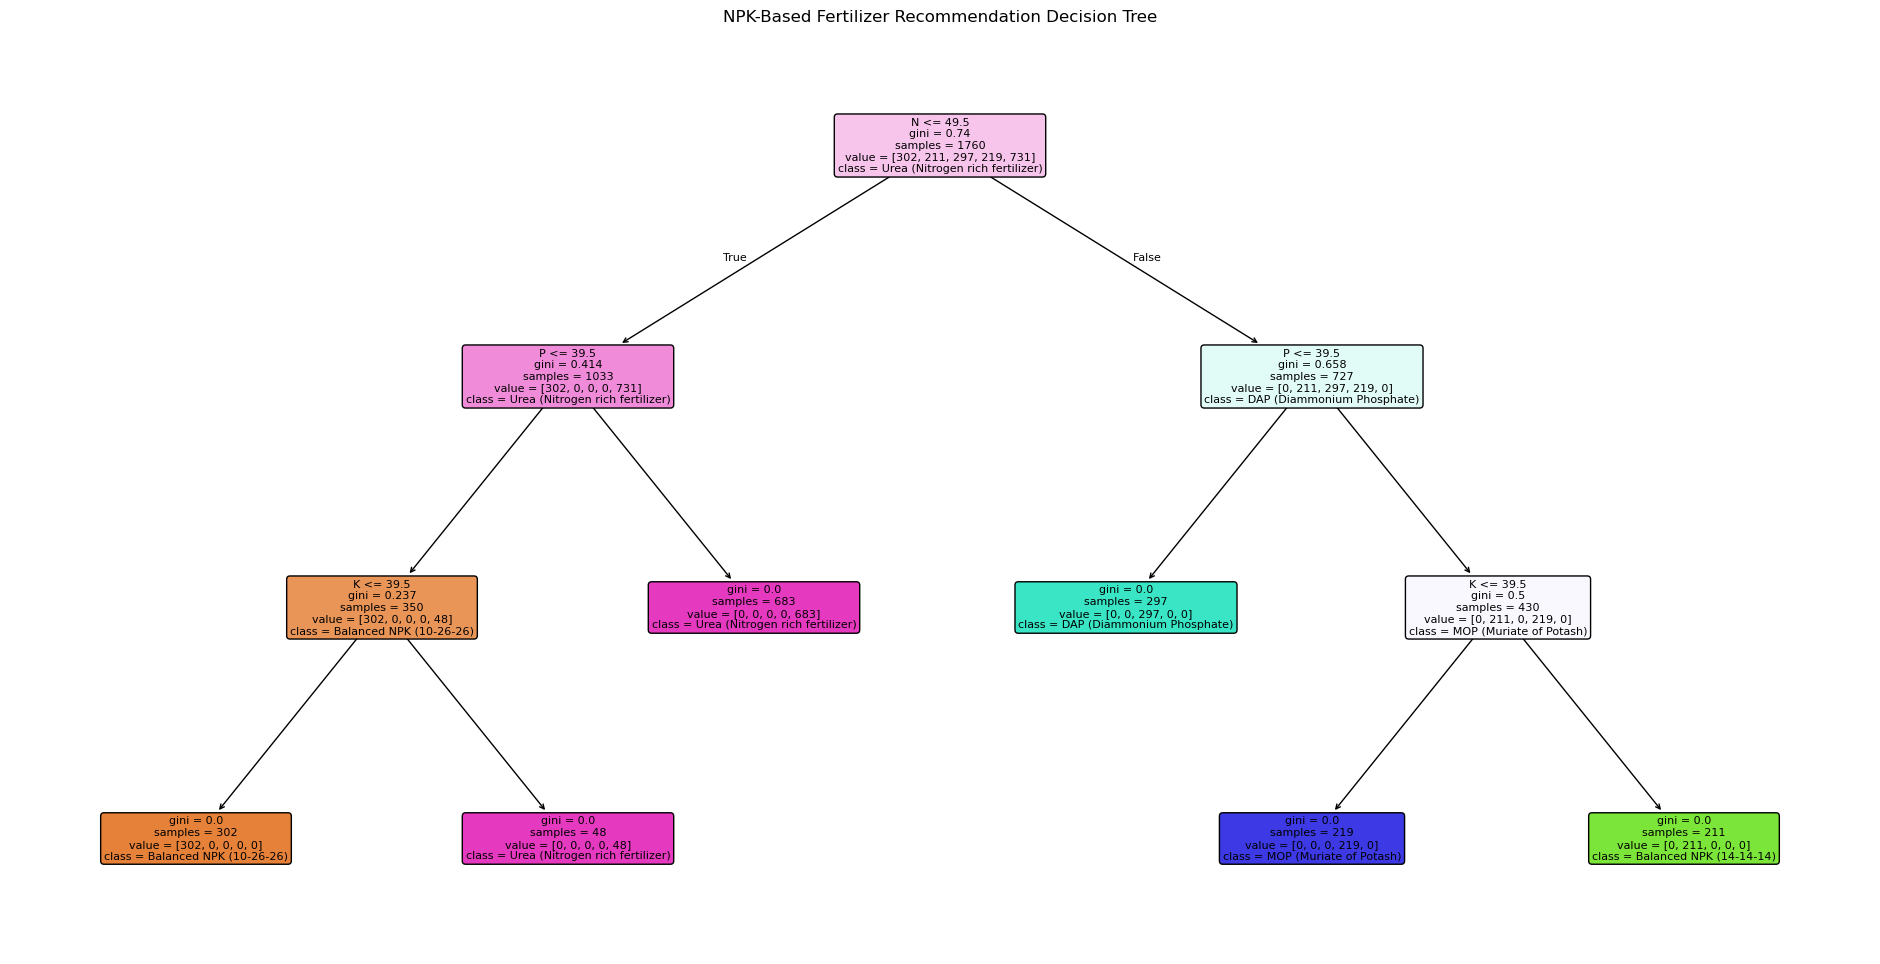

In [68]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    npk_model,
    feature_names=['N', 'P', 'K'],
    class_names=npk_model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title('NPK-Based Fertilizer Recommendation Decision Tree')
plt.show()

In [77]:
from sklearn.tree import export_text

rules = export_text(
    npk_model,
    feature_names=['Nitrogen', 'Phosphorus', 'Potassium']
)

print(rules)

|--- Nitrogen <= 49.50
|   |--- Phosphorus <= 39.50
|   |   |--- Potassium <= 39.50
|   |   |   |--- class: Balanced NPK (10-26-26)
|   |   |--- Potassium >  39.50
|   |   |   |--- class: Urea (Nitrogen rich fertilizer)
|   |--- Phosphorus >  39.50
|   |   |--- class: Urea (Nitrogen rich fertilizer)
|--- Nitrogen >  49.50
|   |--- Phosphorus <= 39.50
|   |   |--- class: DAP (Diammonium Phosphate)
|   |--- Phosphorus >  39.50
|   |   |--- Potassium <= 39.50
|   |   |   |--- class: MOP (Muriate of Potash)
|   |   |--- Potassium >  39.50
|   |   |   |--- class: Balanced NPK (14-14-14)



Classification Report:

                                 precision    recall  f1-score   support

        Balanced NPK (10-26-26)       1.00      1.00      1.00        76
        Balanced NPK (14-14-14)       1.00      1.00      1.00        52
     DAP (Diammonium Phosphate)       1.00      1.00      1.00        74
        MOP (Muriate of Potash)       1.00      1.00      1.00        55
Urea (Nitrogen rich fertilizer)       1.00      1.00      1.00       183

                       accuracy                           1.00       440
                      macro avg       1.00      1.00      1.00       440
                   weighted avg       1.00      1.00      1.00       440



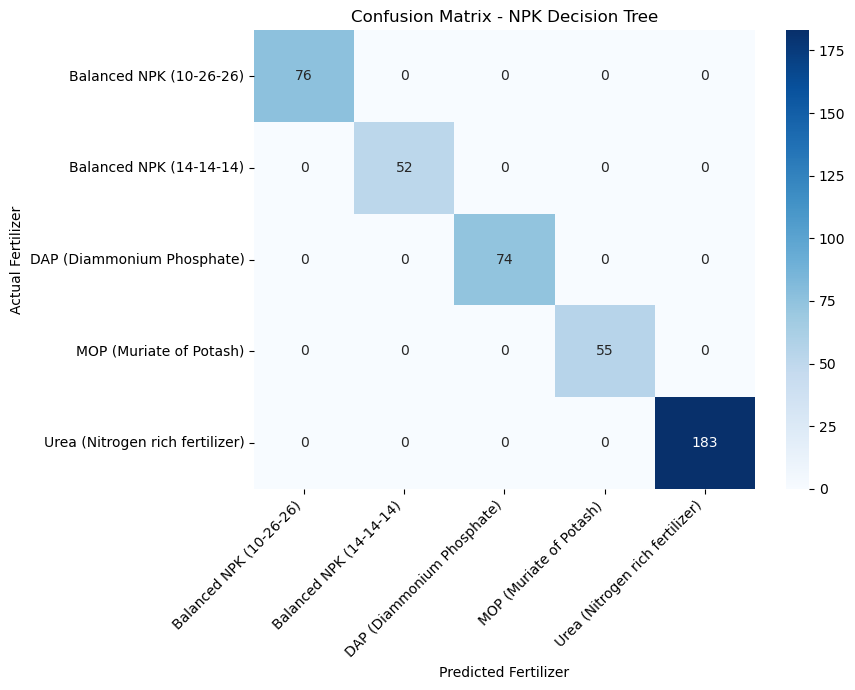

In [83]:
from sklearn.metrics import classification_report, confusion_matrix

# Recreate the NPK-only test dataset
X_npk = df[['N', 'P', 'K']]
y = df['fertilizer']

X_train_npk, X_test_npk, y_train_npk, y_test_npk = train_test_split(
    X_npk,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Predict using the NPK model
y_pred_npk = npk_model.predict(X_test_npk)

# Classification report
print("Classification Report:\n")
print(classification_report(y_test_npk, y_pred_npk))

# Confusion matrix
cm = confusion_matrix(
    y_test_npk,
    y_pred_npk,
    labels=npk_model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=npk_model.classes_,
    yticklabels=npk_model.classes_
)

plt.xlabel('Predicted Fertilizer')
plt.ylabel('Actual Fertilizer')
plt.title('Confusion Matrix - NPK Decision Tree')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [85]:
climate_features = [
    'temperature',
    'humidity',
    'ph',
    'rainfall'
]

X_climate = df[climate_features]
y = df['fertilizer']

X_train_climate, X_test_climate, y_train_climate, y_test_climate = train_test_split(
    X_climate,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

climate_model = DecisionTreeClassifier(random_state=42)

climate_model.fit(X_train_climate, y_train_climate)

climate_predictions = climate_model.predict(X_test_climate)

print("Climate-only Accuracy:",
      accuracy_score(y_test_climate, climate_predictions))

Climate-only Accuracy: 0.740909090909091


In [87]:
baseline_results = pd.DataFrame({
    'Feature Set': [
        'Crop Only',
        'NPK Only',
        'Climate Only',
        'All Features'
    ],
    'Accuracy': [
        accuracy_score(y_test, crop_model.predict(X_test))
        if False else 0.8136363636363636,
        accuracy_score(y_test_npk, y_pred_npk),
        accuracy_score(y_test_climate, climate_predictions),
        1.0
    ]
})

display(baseline_results)

,Feature Set,Accuracy
0,Crop Only,0.813636
1,NPK Only,1.000000
2,Climate Only,0.740909
3,All Features,1.000000


In [89]:
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

y = df['fertilizer']

feature_sets = {
    'Crop Only': ['label'],
    'NPK Only': ['N', 'P', 'K'],
    'Climate Only': ['temperature', 'humidity', 'ph', 'rainfall'],
    'NPK + Crop': ['N', 'P', 'K', 'label'],
    'NPK + Climate': [
        'N', 'P', 'K',
        'temperature', 'humidity', 'ph', 'rainfall'
    ],
    'All Features': [
        'N', 'P', 'K',
        'temperature', 'humidity', 'ph', 'rainfall', 'label'
    ]
}

results = []

for name, features in feature_sets.items():

    X = df[features]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    categorical = X.select_dtypes(include='object').columns.tolist()

    preprocessor = ColumnTransformer([
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical)
    ], remainder='passthrough')

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        'Feature Set': name,
        'Accuracy': accuracy_score(y_test, predictions)
    })

baseline_comparison = pd.DataFrame(results)

display(
    baseline_comparison.sort_values(
        by='Accuracy',
        ascending=False
    )
)

,Feature Set,Accuracy
1,NPK Only,1.000000
3,NPK + Crop,1.000000
4,NPK + Climate,1.000000
5,All Features,1.000000
0,Crop Only,0.813636
2,Climate Only,0.740909


In [91]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_npk = df[['N', 'P', 'K']]
y = df['fertilizer']

dt_model = DecisionTreeClassifier(random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    dt_model,
    X_npk,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Cross-validation scores:", cv_scores)
print("Mean accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [1. 1. 1. 1. 1.]
Mean accuracy: 1.0
Standard deviation: 0.0


In [93]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    'SVM': make_pipeline(
        StandardScaler(),
        SVC()
    ),

    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

X = df[['N', 'P', 'K']]
y = df['fertilizer']

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    model_results.append({
        'Model': name,
        'Mean Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

model_comparison = pd.DataFrame(model_results)

display(
    model_comparison.sort_values(
        by='Mean Accuracy',
        ascending=False
    )
)

,Model,Mean Accuracy,Standard Deviation
0,Decision Tree,1.000000,0.000000
1,Random Forest,1.000000,0.000000
5,Gradient Boosting,1.000000,0.000000
2,KNN,0.952273,0.006098
3,SVM,0.925455,0.012315
4,Logistic Regression,0.912727,0.011097


In [95]:
from sklearn.tree import DecisionTreeClassifier

tree_configs = {
    'Default Tree': DecisionTreeClassifier(random_state=42),
    'Max Depth 3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Max Depth 4': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Min Samples Leaf 5': DecisionTreeClassifier(min_samples_leaf=5, random_state=42),
    'Min Samples Leaf 10': DecisionTreeClassifier(min_samples_leaf=10, random_state=42)
}

tree_results = []

for name, model in tree_configs.items():
    scores = cross_val_score(
        model, X, y, cv=cv, scoring='accuracy'
    )

    tree_results.append({
        'Configuration': name,
        'Mean Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

tree_comparison = pd.DataFrame(tree_results)
display(tree_comparison.sort_values(
    by='Mean Accuracy', ascending=False
))

,Configuration,Mean Accuracy,Standard Deviation
0,Default Tree,1.0,0.0
1,Max Depth 3,1.0,0.0
2,Max Depth 4,1.0,0.0
3,Min Samples Leaf 5,1.0,0.0
4,Min Samples Leaf 10,1.0,0.0


In [106]:
final_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

X = df[['N', 'P', 'K']]
y = df['fertilizer']

final_model.fit(X, y)

print("Tree Depth:", final_model.get_depth())
print("Number of Leaves:", final_model.get_n_leaves())
print("Training Accuracy:", final_model.score(X, y))

Tree Depth: 3
Number of Leaves: 6
Training Accuracy: 1.0


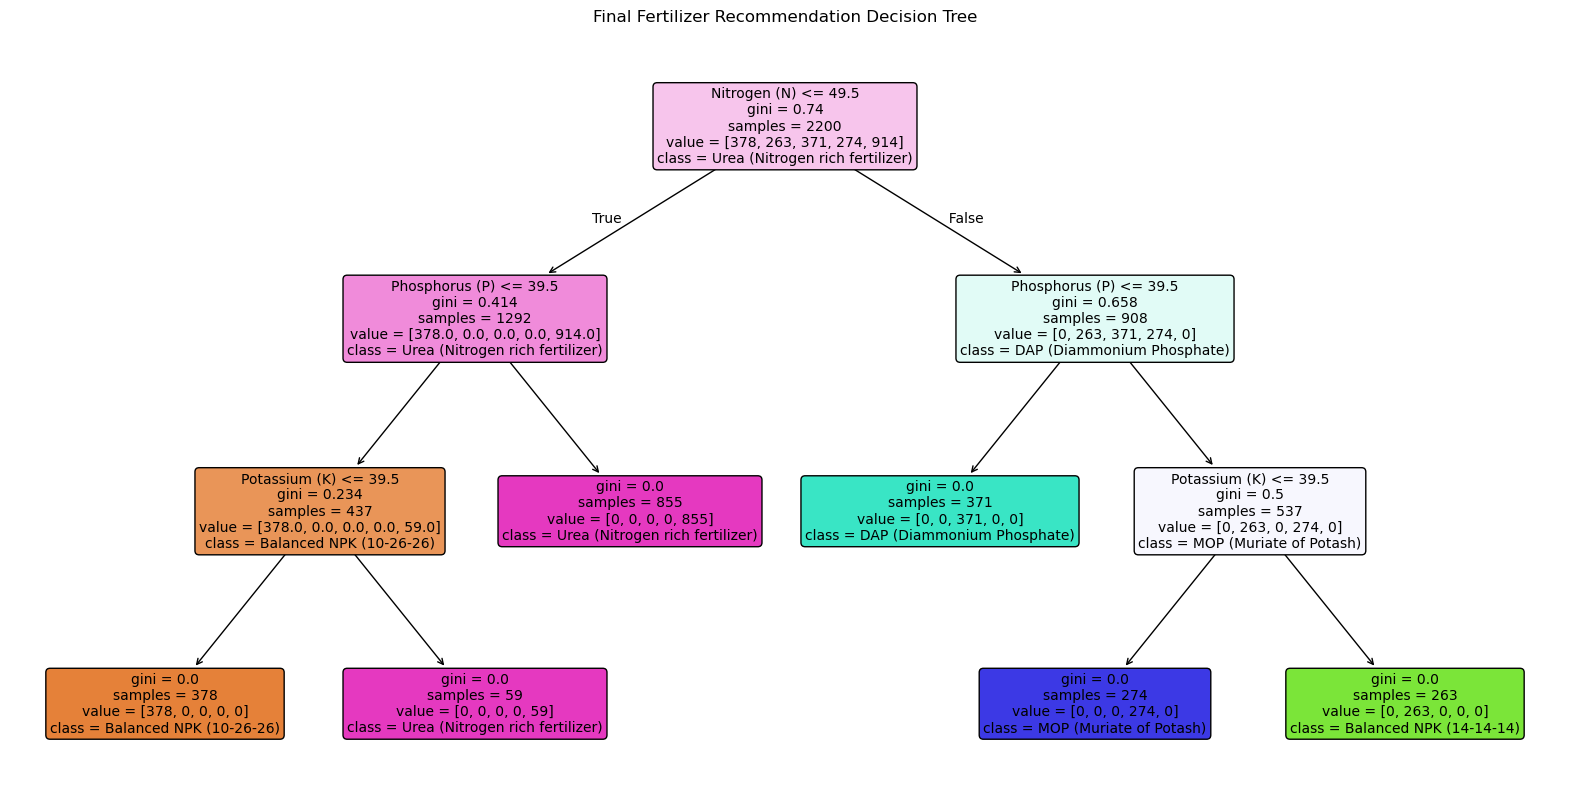

In [108]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    final_model,
    feature_names=['Nitrogen (N)', 'Phosphorus (P)', 'Potassium (K)'],
    class_names=final_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Final Fertilizer Recommendation Decision Tree")
plt.show()

In [110]:
from sklearn.tree import export_text

tree_rules = export_text(
    final_model,
    feature_names=['Nitrogen (N)', 'Phosphorus (P)', 'Potassium (K)']
)

print(tree_rules)


|--- Nitrogen (N) <= 49.50
|   |--- Phosphorus (P) <= 39.50
|   |   |--- Potassium (K) <= 39.50
|   |   |   |--- class: Balanced NPK (10-26-26)
|   |   |--- Potassium (K) >  39.50
|   |   |   |--- class: Urea (Nitrogen rich fertilizer)
|   |--- Phosphorus (P) >  39.50
|   |   |--- class: Urea (Nitrogen rich fertilizer)
|--- Nitrogen (N) >  49.50
|   |--- Phosphorus (P) <= 39.50
|   |   |--- class: DAP (Diammonium Phosphate)
|   |--- Phosphorus (P) >  39.50
|   |   |--- Potassium (K) <= 39.50
|   |   |   |--- class: MOP (Muriate of Potash)
|   |   |--- Potassium (K) >  39.50
|   |   |   |--- class: Balanced NPK (14-14-14)



In [112]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

X = df[['N', 'P', 'K']]
y = df['fertilizer']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

final_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Test Accuracy: 1.0

Classification Report:
                                 precision    recall  f1-score   support

        Balanced NPK (10-26-26)       1.00      1.00      1.00        76
        Balanced NPK (14-14-14)       1.00      1.00      1.00        52
     DAP (Diammonium Phosphate)       1.00      1.00      1.00        74
        MOP (Muriate of Potash)       1.00      1.00      1.00        55
Urea (Nitrogen rich fertilizer)       1.00      1.00      1.00       183

                       accuracy                           1.00       440
                      macro avg       1.00      1.00      1.00       440
                   weighted avg       1.00      1.00      1.00       440


Confusion Matrix:
[[ 76   0   0   0   0]
 [  0  52   0   0   0]
 [  0   0  74   0   0]
 [  0   0   0  55   0]
 [  0   0   0   0 183]]


In [118]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

features = [
    'N', 'P', 'K',
    'temperature', 'humidity', 'ph', 'rainfall',
    'label'
]

X_all = df[features]
y = df['fertilizer']

preprocessor = ColumnTransformer(
    transformers=[
        ('crop_encoder', OneHotEncoder(handle_unknown='ignore'), ['label'])
    ],
    remainder='passthrough'
)

all_feature_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=3, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

all_feature_model.fit(X_train, y_train)

all_predictions = all_feature_model.predict(X_test)

print("All-Feature Test Accuracy:",
      accuracy_score(y_test, all_predictions))

print("\nClassification Report:")
print(classification_report(y_test, all_predictions))

All-Feature Test Accuracy: 1.0

Classification Report:
                                 precision    recall  f1-score   support

        Balanced NPK (10-26-26)       1.00      1.00      1.00        76
        Balanced NPK (14-14-14)       1.00      1.00      1.00        52
     DAP (Diammonium Phosphate)       1.00      1.00      1.00        74
        MOP (Muriate of Potash)       1.00      1.00      1.00        55
Urea (Nitrogen rich fertilizer)       1.00      1.00      1.00       183

                       accuracy                           1.00       440
                      macro avg       1.00      1.00      1.00       440
                   weighted avg       1.00      1.00      1.00       440



In [126]:
import pickle

with open('fertilizer_recommendation_model.pkl', 'wb') as file:
    pickle.dump(all_feature_model, file)

print("All-feature model saved successfully using pickle!")

All-feature model saved successfully using pickle!


In [122]:
import pickle
import pandas as pd

with open('fertilizer_recommendation_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

sample_input = pd.DataFrame([{
    'N': 80,
    'P': 45,
    'K': 50,
    'temperature': 26.5,
    'humidity': 75,
    'ph': 6.5,
    'rainfall': 150,
    'label': 'rice'
}])

prediction = loaded_model.predict(sample_input)

print("Recommended Fertilizer:", prediction[0])

Recommended Fertilizer: Balanced NPK (14-14-14)


In [124]:
import pickle
import pandas as pd

with open('fertilizer_recommendation_model.pkl', 'rb') as file:
    model = pickle.load(file)


def recommend_fertilizer(N, P, K, temperature, humidity, ph, rainfall, crop):
    input_data = pd.DataFrame([{
        'N': N,
        'P': P,
        'K': K,
        'temperature': temperature,
        'humidity': humidity,
        'ph': ph,
        'rainfall': rainfall,
        'label': crop
    }])

    prediction = model.predict(input_data)

    return prediction[0]


result = recommend_fertilizer(
    N=80,
    P=45,
    K=50,
    temperature=26.5,
    humidity=75,
    ph=6.5,
    rainfall=150,
    crop='rice'
)

print("Recommended Fertilizer:", result)

Recommended Fertilizer: Balanced NPK (14-14-14)
